In [1]:
import os
import scanpy as sc
import pandas as pd
import numpy as np

In [2]:
in_dir = "../../data/Amin_NG_2024"
out_dir = "../../results/01_amin_ng_2024/01_load_data"

os.makedirs(out_dir, exist_ok=True)

In [3]:
adata = sc.read_h5ad(f"{in_dir}/GSE211785_Susztak_SC_SN_ATAC_merged_PostSCVI_final.h5ad")

In [4]:
adata

AnnData object with n_obs × n_vars = 338565 × 3000
    obs: 'orig_ident', 'nCount_RNA', 'nFeature_RNA', 'tech', 'percent_mt', 'Gender', 'Status', 'Cluster_Idents', 'nCount_peaks', 'nFeature_peaks', 'total', 'duplicate', 'chimeric', 'unmapped', 'lowmapq', 'mitochondrial', 'nonprimary', 'passed_filters', 'TSS_fragments', 'on_target_fragments', 'peak_region_fragments', 'peak_region_cutsites', 'nucleosome_signal', 'nucleosome_percentile', 'TSS.enrichment', 'TSS.percentile', 'pct_reads_in_peaks', 'nucleosome_group', 'sample', 'sex', 'age', 'group', 'group2'
    var: 'vst.mean-0', 'vst.variance-0', 'vst.variance.expected-0', 'vst.variance.standardized-0', 'vst.variable-0', 'vst.mean-1', 'vst.variance-1', 'vst.variance.expected-1', 'vst.variance.standardized-1', 'vst.variable-1', 'name-2', 'n_counts', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'highly_variable_nbatches'
    uns: 'Cluster_Idents_113Cluster_colors', 'Cluster_Idents_Level1_New_colors', 'Cl

/data/pinello/SHARED_SOFTWARE/envs/zl002_envs/zl_ssc/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:1217: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/data/pinello/SHARED_SOFTWARE/envs/zl002_envs/zl_ssc/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


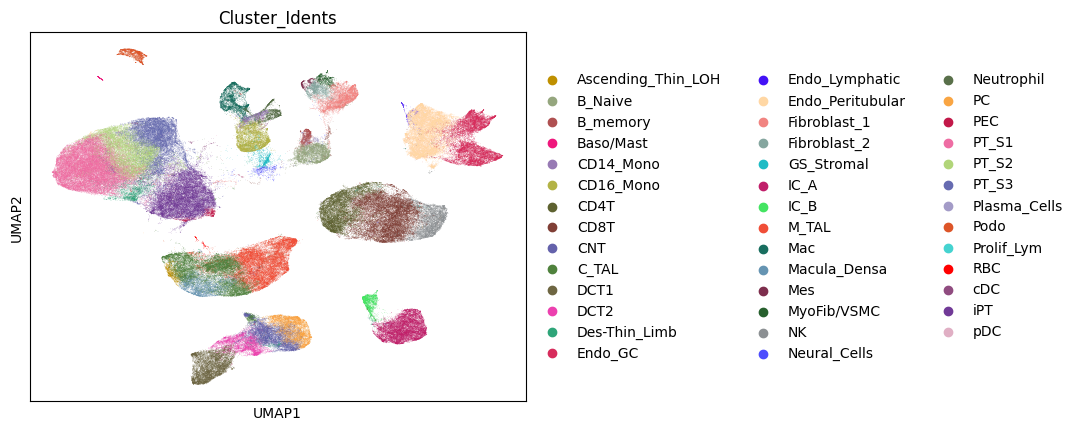

In [5]:
sc.pl.umap(adata, color=['Cluster_Idents'])

In [6]:
adata.obs['cell_type'] = adata.obs['Cluster_Idents']

In [16]:
adata.obs['cell_type'] = adata.obs['cell_type'].str.replace(r'\bB_Naive\b', 'B cells', regex=True)
adata.obs['cell_type'] = adata.obs['cell_type'].str.replace(r'\bB_memory\b', 'B cells', regex=True)
adata.obs['cell_type'] = adata.obs['cell_type'].str.replace(r'\bCD14_Mono\b', 'Monocytes', regex=True)
adata.obs['cell_type'] = adata.obs['cell_type'].str.replace(r'\bCD16_Mono\b', 'Monocytes', regex=True)
adata.obs['cell_type'] = adata.obs['cell_type'].str.replace(r'\bCD4T\b', 'T cells', regex=True)
adata.obs['cell_type'] = adata.obs['cell_type'].str.replace(r'\bCD8T\b', 'T cells', regex=True)
adata.obs['cell_type'] = adata.obs['cell_type'].str.replace(r'\bDCT1\b', 'DCT', regex=True)
adata.obs['cell_type'] = adata.obs['cell_type'].str.replace(r'\bDCT2\b', 'DCT', regex=True)
adata.obs['cell_type'] = adata.obs['cell_type'].str.replace(r'\bEndo_GC\b', 'Endo', regex=True)
adata.obs['cell_type'] = adata.obs['cell_type'].str.replace(r'\bEndo_Lymphatic\b', 'Endo', regex=True)
adata.obs['cell_type'] = adata.obs['cell_type'].str.replace(r'\bEndo_Peritubular\b', 'Endo', regex=True)
adata.obs['cell_type'] = adata.obs['cell_type'].str.replace(r'\bFibroblast_1\b', 'Fibroblast', regex=True)
adata.obs['cell_type'] = adata.obs['cell_type'].str.replace(r'\bFibroblast_2\b', 'Fibroblast', regex=True)
adata.obs['cell_type'] = adata.obs['cell_type'].str.replace(r'\bIC_A\b', 'IC', regex=True)
adata.obs['cell_type'] = adata.obs['cell_type'].str.replace(r'\bIC_B\b', 'IC', regex=True)
adata.obs['cell_type'] = adata.obs['cell_type'].str.replace(r'\bC_TAL\b', 'TAL', regex=True)
adata.obs['cell_type'] = adata.obs['cell_type'].str.replace(r'\bM_TAL\b', 'TAL', regex=True)
adata.obs['cell_type'] = adata.obs['cell_type'].str.replace(r'\bPT_S1\b', 'PT', regex=True)
adata.obs['cell_type'] = adata.obs['cell_type'].str.replace(r'\bPT_S2\b', 'PT', regex=True)
adata.obs['cell_type'] = adata.obs['cell_type'].str.replace(r'\bPT_S3\b', 'PT', regex=True)

In [17]:
adata.obs['cell_type'] = adata.obs['cell_type'].astype('category')

/data/pinello/SHARED_SOFTWARE/envs/zl002_envs/zl_ssc/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:1217: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/data/pinello/SHARED_SOFTWARE/envs/zl002_envs/zl_ssc/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


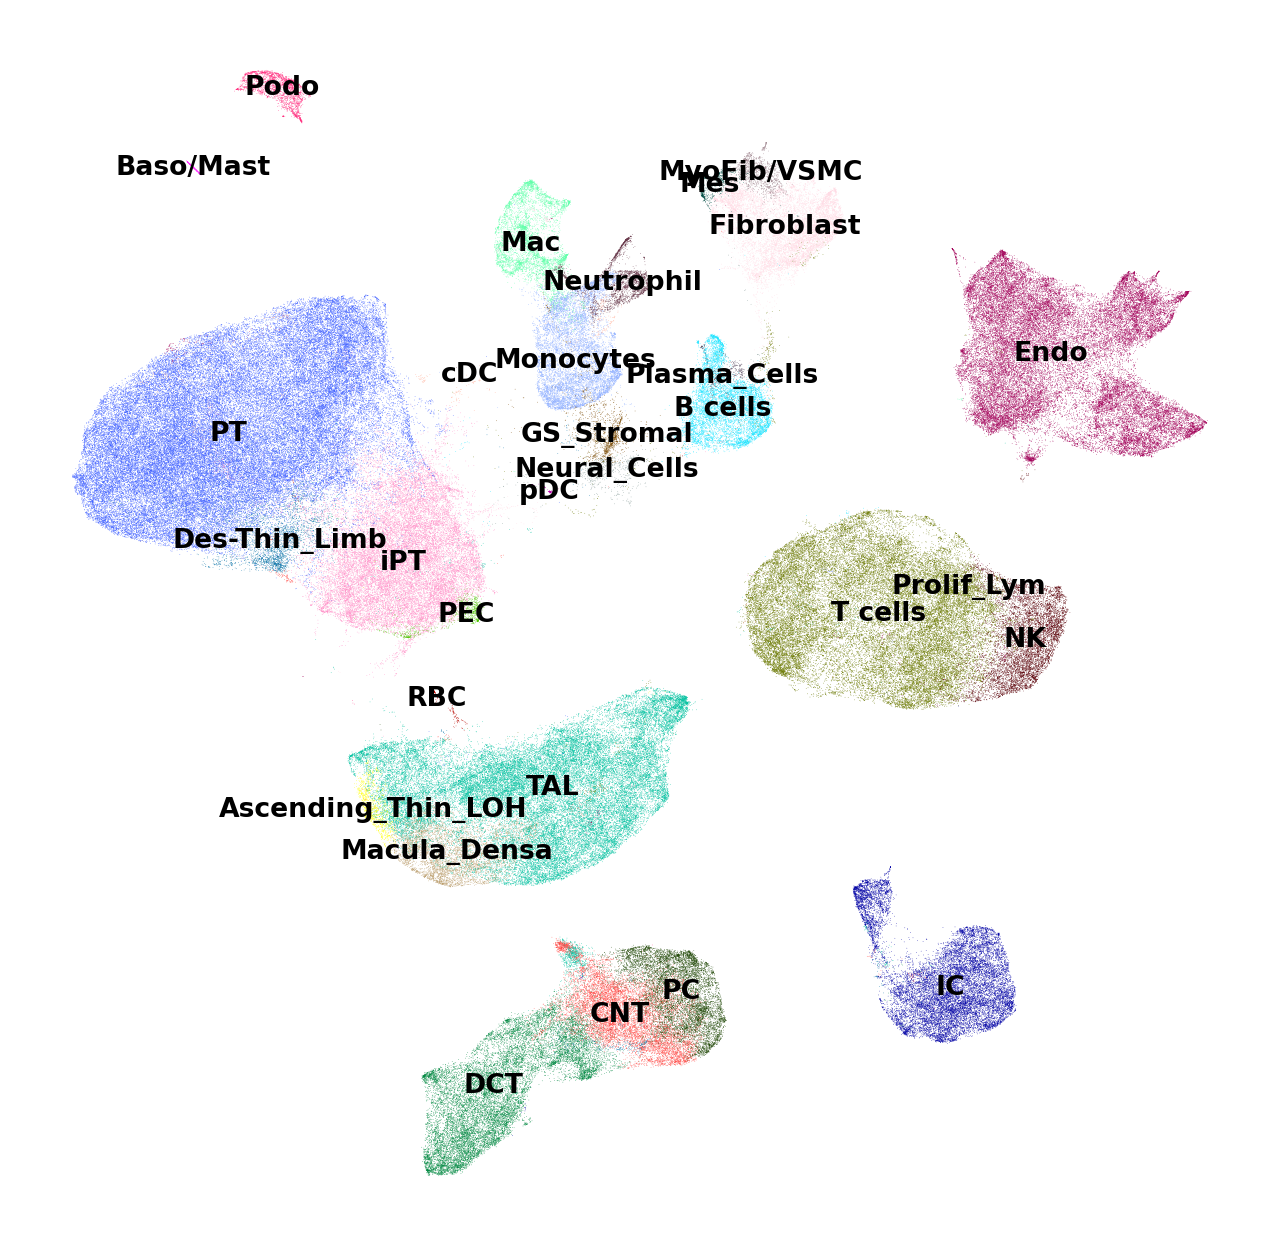

In [24]:
sc.set_figure_params(figsize=(10, 10))

sc.pl.umap(adata, color=['cell_type'], legend_loc='on data', legend_fontsize=12, title='', frameon=False)